# 12 · IBM Quantum hardware

Three small experiments in **one job** (about 100 circuits × 4000 shots, roughly 2–3 minutes of QPU time):

| Exp. | Question | Circuits |
| --- | --- | --- |
| A | Phase 1 on hardware: are the η, φ probabilities (10⁻⁷–2·10⁻³) above the hardware error level? | 6 jets, raw (pT, η, φ, m) amplitude encoding, + 1 empty reference circuit |
| B | Concentration on hardware: do measured kernel values follow the exact ones? | 28 jet pairs × {raw, min-max} amplitude encoding (QGL inputs), compute–uncompute |
| C | Qubit number: how does hardware noise change the kernel as qubits are added? | rotation-invariant 1P1Q, N = 2, 4, 6, 8, 10 qubits; 6 pairs + 1 self-pair each |

Kernel entries are measured with the compute–uncompute circuit $U(x_j)^\dagger U(x_i)$: the probability of the all-zero outcome is $|\langle\psi(x_j)|\psi(x_i)\rangle|^2$.
No error mitigation is applied: the point is to see raw hardware behaviour.

**Order of work:** (1) install and save your account once, (2) run with `DRY_RUN = True` (local simulator, no QPU time),
(3) set `DRY_RUN = False` and submit, (4) analyse. Never commit your API key.

> **Note added after the independent review (11 Nov 2026).**

- **A.** The empty reference circuit was transpiled on its own (no fixed `initial_layout`), so it probably ran on different physical qubits from the jet circuits: it shows more "10" outcomes (31/4000) than any jet circuit (11–18/4000), which is very unlikely on the same qubits (notebook 15, part C). Its numbers are therefore **not** the readout floor of the jet circuits. Correct statement: the η, φ probabilities (10⁻⁷–2·10⁻³) are below the total gate + readout error (≈ 3·10⁻³–10⁻²).
- **B.** Raw amplitude: the mean hardware offset (≈ 0.011) is larger than the whole range of exact values (0.993–1.000); Pearson 0.92 but Spearman 0.70, 28 pairs from only 8 jets, so the ordering is only partly preserved. Min-max: Pearson 0.999, fit slope 0.95, intercept 0.03 (a ~5 % contraction). The figure legend rounds r to two decimals.
- **C.** The compute–uncompute circuits of the rotation-invariant 1P1Q are products of single-qubit RY rotations: there are no two-qubit gates, and without a barrier the transpiler (optimization_level = 1) merges RY(θ)·RY(−θ′) into one rotation (removed entirely for self-pairs). Experiment C therefore measures how the readout error of the all-zeros outcome grows with the number of qubits, not circuit noise.
- The output of the last cell (section 6) came from the dry run and has been cleared; the hardware numbers are in sections 4–5 and in the research log.

## 0. One-time setup (Terminal, then this cell once)

```bash
conda activate qt4hep
pip install qiskit-ibm-runtime
```

Get your API key on quantum.cloud.ibm.com (profile → API key). Paste it below, run the cell **once**, then delete the key from the cell.

In [ ]:
# from qiskit_ibm_runtime import QiskitRuntimeService
# QiskitRuntimeService.save_account(token="PASTE_API_KEY_HERE", channel="ibm_quantum_platform",
#                                   set_as_default=True, overwrite=True)

## 1. Settings and circuits

In [8]:
import sys
sys.path.insert(0, "src")

import json
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit

from jet_data import (load_jets, select_quark_gluon, feature_matrix, event_level_split, balanced_subsample,
                      leading_constituents, BOOKKEEPING, PF_KEYS)
from quantum_encodings import amplitude_encoding_circuit
from kernels import preprocess, amplitude_kernel, angle_kernel
from figure_style import set_style, save, COLORS

DRY_RUN = False          # True: local exact simulator, no QPU time. Set to False to submit to IBM hardware.
SHOTS = 4000
SEED = 42
F_1P1Q = 39.0           # rotation-invariant 1P1Q scale (median learned value, notebook 09)
N_LIST = [2, 4, 6, 8, 10]
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
set_style()

KIN = ("jetPt", "jetEta", "jetPhi", "jetMass")
QGL = ("QG_mult", "QG_ptD", "QG_axis2")
jets = select_quark_gluon(load_jets(features=KIN + QGL, extra=BOOKKEEPING + PF_KEYS), require_loose_id=True)
y = jets["label"]
train, test = event_level_split(jets, test_fraction=0.3, seed=SEED)
X_kin = feature_matrix(jets, features=KIN)
X_qgl = feature_matrix(jets, features=QGL)
z, d_eta, d_phi, _ = leading_constituents(jets, n_max=max(N_LIST))
d_r = np.sqrt(d_eta**2 + d_phi**2)

rng = np.random.default_rng(SEED)
test_idx = np.flatnonzero(test)
jets_A = rng.choice(test_idx, size=6, replace=False)
jets_B = np.concatenate([rng.choice(test_idx[y[test_idx] == c], size=4, replace=False) for c in (1, 0)])
pairs_B = [(i, j) for a, i in enumerate(jets_B) for j in jets_B[a + 1:]]
jets_C = rng.choice(test_idx, size=7, replace=False)
pairs_C = [(jets_C[k], jets_C[k + 1]) for k in range(6)]

def measured(qc):
    qc = qc.copy(); qc.measure_all(); return qc

def compute_uncompute(c_i, c_j):
    qc = c_i.copy(); qc.compose(c_j.inverse(), inplace=True); return qc

def angle_circuit(theta):
    qc = QuantumCircuit(len(theta))
    for q, t in enumerate(theta):
        qc.ry(float(t), q)
    return qc

circuits, meta = [], []

# A: raw kinematic amplitude encoding + empty reference circuit
circuits.append(measured(QuantumCircuit(2))); meta.append({"exp": "A", "kind": "reference"})
for j in jets_A:
    circuits.append(measured(amplitude_encoding_circuit(X_kin[j])))
    meta.append({"exp": "A", "kind": "jet", "jet": int(j), "exact": (X_kin[j]**2 / np.sum(X_kin[j]**2)).tolist()})

# B: amplitude kernel entries, raw and min-max (min-max fitted on the seed-0 training subsample, as in notebook 05)
fit_idx = balanced_subsample(y, train, 200, seed=0)
X_B = {"raw": X_qgl, "minmax": preprocess("minmax", X_qgl[fit_idx], X_qgl)[1]}
for prep, XB in X_B.items():
    for i, j in pairs_B:
        k_exact = float(amplitude_kernel(XB[[i]], XB[[j]])[0, 0])
        circuits.append(measured(compute_uncompute(amplitude_encoding_circuit(XB[i]), amplitude_encoding_circuit(XB[j]))))
        meta.append({"exp": "B", "prep": prep, "pair": [int(i), int(j)], "same_class": bool(y[i] == y[j]), "exact": k_exact})

# C: rotation-invariant 1P1Q, increasing qubit number
for n in N_LIST:
    theta = F_1P1Q * z[:, :n] * d_r[:, :n]
    for i, j in pairs_C + [(jets_C[0], jets_C[0])]:
        k_exact = float(angle_kernel(theta[[i]], theta[[j]])[0, 0])
        circuits.append(measured(compute_uncompute(angle_circuit(theta[i]), angle_circuit(theta[j]))))
        meta.append({"exp": "C", "n_qubits": n, "pair": [int(i), int(j)], "self": bool(i == j), "exact": k_exact})

print(f"{len(circuits)} circuits: A {sum(m['exp'] == 'A' for m in meta)}, B {sum(m['exp'] == 'B' for m in meta)}, C {sum(m['exp'] == 'C' for m in meta)}")

98 circuits: A 7, B 56, C 35


## 2. Run (dry run first)

In [9]:
if DRY_RUN:
    from qiskit.primitives import StatevectorSampler
    backend_name = "local StatevectorSampler (dry run)"
    job = StatevectorSampler(seed=SEED).run(circuits, shots=SHOTS)
    job_id = "dry-run"
else:
    from qiskit.transpiler import generate_preset_pass_manager
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    service = QiskitRuntimeService()
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=max(N_LIST))
    backend_name = backend.name
    pm = generate_preset_pass_manager(optimization_level=1, backend=backend)
    isa = pm.run(circuits)
    two_q = [sum(v for k, v in c.count_ops().items() if k in ("cx", "cz", "ecr")) for c in isa]
    print(f"backend {backend_name}; max depth {max(c.depth() for c in isa)}; max two-qubit gates per circuit {max(two_q)}")
    job = SamplerV2(mode=backend).run(isa, shots=SHOTS)
    job_id = job.job_id()

run_info = {"job_id": job_id, "backend": backend_name, "shots": SHOTS, "dry_run": DRY_RUN,
            "submitted_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")}
json.dump({"run": run_info, "meta": meta}, open(RESULTS / ("ibm_job_dryrun.json" if DRY_RUN else "ibm_job.json"), "w"), indent=2)
print(run_info)
print("Waiting for results (on hardware this includes queue time; you can close the notebook and use the next cell later).")

qiskit_runtime_service.__init__:WARNING:2026-11-10 14:32:45,802: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: CERN QT4HEP. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-10 14:32:46,173: Loading instance: CERN QT4HEP, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-10 14:32:47,911: Using instance: CERN QT4HEP, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-10 14:32:48,745: Using instance: CERN QT4HEP, plan: open


backend ibm_marrakesh; max depth 18; max two-qubit gates per circuit 2
{'job_id': 'dbpg1o8qtr0c738ebupg', 'backend': 'ibm_marrakesh', 'shots': 4000, 'dry_run': False, 'submitted_utc': '2026-11-10T11:32:49+00:00'}
Waiting for results (on hardware this includes queue time; you can close the notebook and use the next cell later).


## 3. Retrieve results

If the kernel was restarted while the job was queued, set `JOB_ID` and run this cell to fetch the finished job.

In [10]:
JOB_ID = None   # e.g. "d4abc123..." from results/ibm_job.json, only needed after a restart
if JOB_ID is not None:
    from qiskit_ibm_runtime import QiskitRuntimeService
    job = QiskitRuntimeService().job(JOB_ID)
    saved = json.load(open(RESULTS / "ibm_job.json")); meta, run_info = saved["meta"], saved["run"]

result = job.result()
counts = [result[k].data.meas.get_counts() for k in range(len(meta))]
n_bits = lambda m: 2 if m["exp"] in ("A", "B") else m["n_qubits"]
def prob(c, bitstring): return c.get(bitstring, 0) / SHOTS
json.dump({"run": run_info, "meta": meta, "counts": counts},
          open(RESULTS / ("ibm_results_dryrun.json" if run_info["dry_run"] else "ibm_results.json"), "w"), indent=2)
print("results saved;", run_info["backend"])

results saved; ibm_marrakesh


## 4. Experiment A: Phase 1 on hardware

In [11]:
ref = counts[0]
floor = {b: prob(ref, b) for b in ("01", "10", "11")}
print(f"Empty circuit (ideal: always 00): P(01) = {floor['01']:.4f}, P(10) = {floor['10']:.4f}, P(11) = {floor['11']:.4f}  <- readout noise floor")
print()
print(f"{'jet':>6s} {'state':>6s} {'exact':>10s} {'measured':>10s}")
for m, c in zip(meta, counts):
    if m["exp"] == "A" and m["kind"] == "jet":
        for i, label in enumerate(["00 pT", "01 eta", "10 phi", "11 m"]):
            print(f"{m['jet']:6d} {label:>6s} {m['exact'][i]:10.2e} {prob(c, format(i, '02b')):10.2e}")
        print()

Empty circuit (ideal: always 00): P(01) = 0.0013, P(10) = 0.0077, P(11) = 0.0000  <- readout noise floor

   jet  state      exact   measured
  9007  00 pT   9.66e-01   9.57e-01
  9007 01 eta   2.61e-05   7.00e-03
  9007 10 phi   4.55e-04   4.00e-03
  9007   11 m   3.32e-02   3.18e-02

 10669  00 pT   9.84e-01   9.70e-01
 10669 01 eta   1.27e-05   5.75e-03
 10669 10 phi   1.21e-05   3.00e-03
 10669   11 m   1.59e-02   2.10e-02

  6133  00 pT   9.80e-01   9.69e-01
  6133 01 eta   3.85e-04   6.50e-03
  6133 10 phi   1.55e-03   4.50e-03
  6133   11 m   1.81e-02   2.05e-02

 11718  00 pT   9.58e-01   9.51e-01
 11718 01 eta   1.93e-03   9.50e-03
 11718 10 phi   2.06e-04   3.75e-03
 11718   11 m   3.97e-02   3.55e-02

  6195  00 pT   9.88e-01   9.78e-01
  6195 01 eta   1.04e-05   6.50e-03
  6195 10 phi   2.23e-05   3.50e-03
  6195   11 m   1.18e-02   1.18e-02

  1271  00 pT   9.91e-01   9.82e-01
  1271 01 eta   1.09e-07   5.25e-03
  1271 10 phi   3.74e-06   2.75e-03
  1271   11 m   8.56e-03 

## 5. Experiments B and C: figure

B, raw   : exact K in [0.9930, 1.0000], measured in [0.9802, 0.9918], correlation 0.92
B, minmax: exact K in [0.2003, 0.9929], measured in [0.2415, 0.9775], correlation 1.00
saved figures/fig13_ibm_hardware.pdf and .png


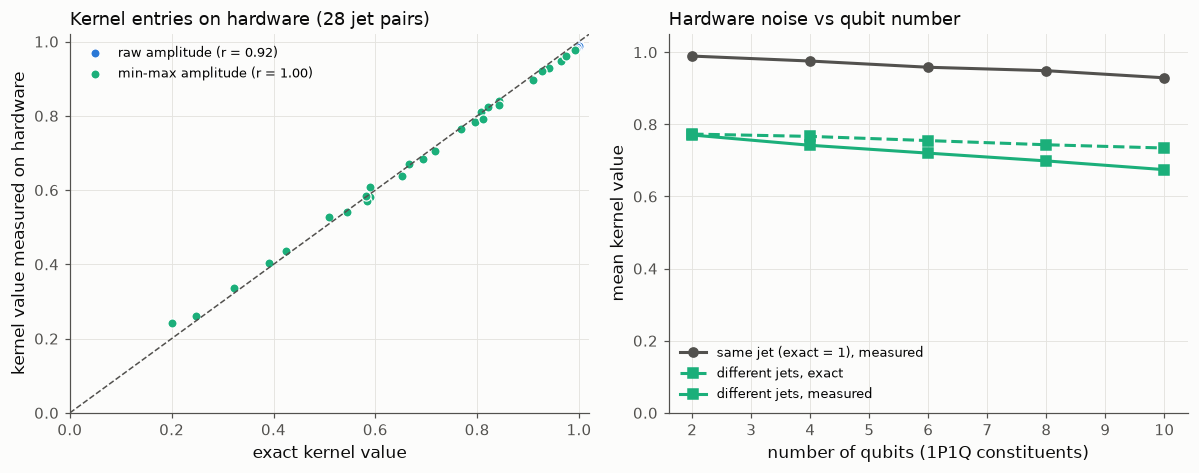


qubits  self, measured  pairs, exact  pairs, measured
     2           0.989         0.773            0.770
     4           0.976         0.767            0.742
     6           0.958         0.755            0.720
     8           0.949         0.743            0.699
    10           0.929         0.734            0.674


In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))

for prep, col, lab in (("raw", COLORS["series1"], "raw amplitude"), ("minmax", COLORS["series3"], "min-max amplitude")):
    sel = [(m, c) for m, c in zip(meta, counts) if m["exp"] == "B" and m["prep"] == prep]
    ex = np.array([m["exact"] for m, _ in sel]); hw = np.array([prob(c, "00") for _, c in sel])
    r = np.corrcoef(ex, hw)[0, 1] if ex.std() > 0 and hw.std() > 0 else np.nan
    ax1.scatter(ex, hw, s=36, color=col, edgecolors="white", linewidths=0.8, label=f"{lab} (r = {r:.2f})")
    print(f"B, {prep:6s}: exact K in [{ex.min():.4f}, {ex.max():.4f}], measured in [{hw.min():.4f}, {hw.max():.4f}], correlation {r:.2f}")
lims = [0, 1.02]
ax1.plot(lims, lims, color=COLORS["reference"], linestyle="--", linewidth=1)
ax1.set_xlim(lims); ax1.set_ylim(lims)
ax1.set_xlabel("exact kernel value"); ax1.set_ylabel("kernel value measured on hardware")
ax1.set_title("Kernel entries on hardware (28 jet pairs)", loc="left")
ax1.legend(loc="upper left", fontsize=8.5)

ns = np.array(N_LIST)
self_hw, pair_hw, pair_ex = [], [], []
for n in N_LIST:
    sel = [(m, c) for m, c in zip(meta, counts) if m["exp"] == "C" and m["n_qubits"] == n]
    zero = "0" * n
    self_hw.append(np.mean([prob(c, zero) for m, c in sel if m["self"]]))
    pair_hw.append(np.mean([prob(c, zero) for m, c in sel if not m["self"]]))
    pair_ex.append(np.mean([m["exact"] for m, c in sel if not m["self"]]))
ax2.plot(ns, self_hw, "o-", color=COLORS["reference"], label="same jet (exact = 1), measured")
ax2.plot(ns, pair_ex, "s--", color=COLORS["series3"], label="different jets, exact")
ax2.plot(ns, pair_hw, "s-", color=COLORS["series3"], label="different jets, measured")
ax2.set_ylim(0, 1.05)
ax2.set_xlabel("number of qubits (1P1Q constituents)"); ax2.set_ylabel("mean kernel value")
ax2.set_title("Hardware noise vs qubit number", loc="left")
ax2.legend(loc="lower left", fontsize=8.5)
fig.tight_layout()
save(fig, "fig13_ibm_hardware" + ("_dryrun" if run_info["dry_run"] else ""))
plt.show()

print()
print(f"{'qubits':>6s} {'self, measured':>15s} {'pairs, exact':>13s} {'pairs, measured':>16s}")
for n, a, b, c in zip(N_LIST, self_hw, pair_ex, pair_hw):
    print(f"{n:6d} {a:15.3f} {b:13.3f} {c:16.3f}")

## 6. Summary for the research log

In [ ]:
print(f"- IBM run: backend {run_info['backend']}, job {run_info['job_id']}, {SHOTS} shots, {run_info['submitted_utc']}, no error mitigation")
print(f"- A: readout floor P(01)={floor['01']:.4f}, P(10)={floor['10']:.4f}, P(11)={floor['11']:.4f}")
print("- C: self-overlap vs qubits: " + ", ".join(f"{n}q {v:.3f}" for n, v in zip(N_LIST, self_hw)))